# 05 — Toronto observed heat-event weather and SOLWEIG

## Purpose

This notebook replaces the earlier EPW-based timestep selection with a
**documented Toronto heat-event scenario**.

We use:

- **event date:** 25 July 2025
- **event time:** 15:00 local Toronto time
- **event context:** this date falls within Toronto's documented
  **23–30 July 2025 heat-warning period**
- **weather source:** historical hourly weather queried at the U of T pilot
  location using the Open-Meteo historical archive

The historical archive is used because it provides the full hourly weather
variables needed by SOLWEIG in one reproducible query, including:

- air temperature;
- relative humidity;
- wind speed;
- shortwave/global solar radiation.

This should be interpreted as a **historical gridded weather reconstruction
for a documented heat-warning event**, rather than a station-only observation.

The primary output is:

**`utci_2025-07-25_1500.tif`**

Every cell therefore represents the **same real heat-event date and same
common local time**.

**Kernel:** Python 3.12 - VoxCity

## 1. Imports and project paths

In [1]:
from pathlib import Path
from datetime import datetime
import json
import sys

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
import requests

import solweig

HERE = Path.cwd().resolve()

if HERE.name == "notebooks_toronto_v02":
    PROJECT_ROOT = HERE.parent
elif (HERE / "notebooks_toronto_v02").exists():
    PROJECT_ROOT = HERE
else:
    PROJECT_ROOT = Path(
        "/scratch/project_2010417/paper3/heat-conditioned-accessibility"
    )

TORONTO_DATA = PROJECT_ROOT / "data" / "toronto"
TORONTO_RAW = TORONTO_DATA / "raw"
TORONTO_INTERIM = TORONTO_DATA / "interim"
TORONTO_OUTPUTS = PROJECT_ROOT / "outputs" / "toronto"

SOLWEIG_INPUT_DIR = (
    TORONTO_INTERIM
    / "solweig"
    / "UOFT_PILOT"
)

SOLWEIG_CACHE_DIR = (
    TORONTO_INTERIM
    / "solweig_cache"
    / "UOFT_PILOT"
)

WEATHER_DIR = (
    TORONTO_RAW
    / "weather"
)

SOLWEIG_OUTPUT_DIR = (
    TORONTO_OUTPUTS
    / "solweig"
    / "UOFT_PILOT_2025-07-25_1500"
)

for folder in [
    SOLWEIG_CACHE_DIR,
    WEATHER_DIR,
    SOLWEIG_OUTPUT_DIR,
]:
    folder.mkdir(
        parents=True,
        exist_ok=True,
    )

print("Python:", sys.version)
print(
    "SOLWEIG version:",
    getattr(solweig, "__version__", "unknown"),
)
print("Project root:", PROJECT_ROOT)

Python: 3.12.15 (main, Oct 13 2026, 16:52:04) [GCC 15.3.0]
SOLWEIG version: 0.1.0b96
Project root: /scratch/project_2010417/paper3/heat-conditioned-accessibility


## 2. Define the documented Toronto heat-event scenario

The scenario is fixed deliberately rather than selected from a typical
meteorological year.

`25 July 2025` lies inside the documented Toronto heat-warning period
`23–30 July 2025`.

We use **15:00 local Toronto time** as a common hot-afternoon timestep.

In [2]:
EVENT_DATE = "2025-07-25"
EVENT_HOUR = 15
TORONTO_TIMEZONE = "America/Toronto"

event_datetime = pd.Timestamp(
    f"{EVENT_DATE} {EVENT_HOUR:02d}:00:00",
    tz=TORONTO_TIMEZONE,
)

print("Heat-event date:", EVENT_DATE)
print("Common local time:", f"{EVENT_HOUR:02d}:00")
print("Timezone:", TORONTO_TIMEZONE)
print("Timestamp:", event_datetime)

Heat-event date: 2025-07-25
Common local time: 15:00
Timezone: America/Toronto
Timestamp: 2025-07-25 15:00:00-04:00


## 3. Load the U of T pilot location

In [3]:
campus_center_path = (
    TORONTO_RAW
    / "toronto_uoft_center.gpkg"
)

if not campus_center_path.exists():
    raise FileNotFoundError(
        f"Campus center not found: {campus_center_path}"
    )

campus_center = gpd.read_file(
    campus_center_path
).to_crs(4326)

latitude = float(
    campus_center.geometry.y.iloc[0]
)

longitude = float(
    campus_center.geometry.x.iloc[0]
)

print("U of T latitude :", latitude)
print("U of T longitude:", longitude)

U of T latitude : 43.66371033567467
U of T longitude: -79.39600762899782


## 4. Load and validate the final SOLWEIG input rasters

These should come from the cleaned Notebook 04:

- `dem.tif` = real terrain;
- `dsm.tif` = real terrain + Toronto building heights;
- `cdsm.tif` = canopy height.

In [4]:
dsm_path = SOLWEIG_INPUT_DIR / "dsm.tif"
cdsm_path = SOLWEIG_INPUT_DIR / "cdsm.tif"
dem_path = SOLWEIG_INPUT_DIR / "dem.tif"

for path in [
    dsm_path,
    cdsm_path,
    dem_path,
]:
    if not path.exists():
        raise FileNotFoundError(
            f"Required SOLWEIG input missing: {path}"
        )

validation_rows = []
metadata = []

for path in [
    dem_path,
    dsm_path,
    cdsm_path,
]:
    with rasterio.open(path) as src:

        array = src.read(1)

        validation_rows.append(
            {
                "file": path.name,
                "crs": str(src.crs),
                "width": src.width,
                "height": src.height,
                "res_x": src.res[0],
                "res_y": src.res[1],
                "min": float(np.nanmin(array)),
                "mean": float(np.nanmean(array)),
                "max": float(np.nanmax(array)),
            }
        )

        metadata.append(
            (
                src.shape,
                src.crs,
                src.transform,
                src.bounds,
            )
        )

display(
    pd.DataFrame(
        validation_rows
    )
)

if not all(
    item == metadata[0]
    for item in metadata[1:]
):
    raise RuntimeError(
        "DEM, DSM, and CDSM are not perfectly aligned."
    )

print(
    "✓ Final surface rasters are aligned."
)

,file,crs,width,height,res_x,res_y,min,mean,max
0,dem.tif,EPSG:32617,416,416,5.0,5.0,88.739685,107.207680,119.850327
1,dsm.tif,EPSG:32617,416,416,5.0,5.0,88.739685,107.678024,216.928650
2,cdsm.tif,EPSG:32617,416,416,5.0,5.0,0.000000,0.126081,13.978206


✓ Final surface rasters are aligned.


## 5. Prepare the SOLWEIG surface

Spatial preprocessing is cached so later weather scenarios can reuse the same
U of T surface.

In [5]:
surface = solweig.SurfaceData.prepare(
    dsm=str(dsm_path),
    cdsm=str(cdsm_path),
    dem=str(dem_path),
    working_dir=str(
        SOLWEIG_CACHE_DIR
    ),
)

print(
    "✓ SOLWEIG surface prepared."
)

solweig.models.surface: Fast-path cache invalidated (1 change):
solweig.models.surface:   - kwarg 'pixel_size' changed (5.0 → None)
solweig.models.surface: Rebuilding from source rasters…
solweig.models.surface: Preparing surface data from GeoTIFF files...
solweig.models.surface_loading:   DSM: 416×416 pixels
solweig.models.surface_loading:   Extracted pixel size from DSM: 5.00 m
solweig.models.surface_loading:   CRS validated: WGS 84 / UTM zone 17N (EPSG:32617)
solweig.models.surface_loading:   ✓ Canopy DSM (CDSM) provided
solweig.models.surface_loading:   ✓ Ground elevation (DEM) provided
solweig.models.surface_loading:   → No TDSM provided - will auto-generate from CDSM (ratio=0.25)
solweig.models.surface_loading: Checking for preprocessing data...
solweig.io: No-data value is -9999.0, replacing with NaN
solweig.io: No-data value is -9999.0, replacing with NaN
solweig.models.surface_loading:   ✓ Walls found in working_dir: /scratch/project_2010417/paper3/heat-conditioned-accessibili

## 6. Download historical hourly weather for the heat-event day

We request the full event day from the Open-Meteo historical archive at the
U of T coordinates.

Required SOLWEIG weather variables:

- temperature at 2 m;
- relative humidity at 2 m;
- wind speed at 10 m;
- shortwave radiation.

The API response is requested directly in `America/Toronto` local time.

In [6]:
weather_url = (
    "https://archive-api.open-meteo.com/v1/archive"
)

params = {
    "latitude": latitude,
    "longitude": longitude,
    "start_date": EVENT_DATE,
    "end_date": EVENT_DATE,
    "hourly": (
        "temperature_2m,"
        "relative_humidity_2m,"
        "wind_speed_10m,"
        "shortwave_radiation"
    ),
    "timezone": TORONTO_TIMEZONE,
    "wind_speed_unit": "ms",
}

response = requests.get(
    weather_url,
    params=params,
    timeout=60,
)

response.raise_for_status()

weather_json = response.json()

print(
    "Weather query completed."
)

print(
    "Timezone returned:",
    weather_json.get(
        "timezone"
    ),
)

Weather query completed.
Timezone returned: America/Toronto


## 7. Convert the historical weather response to a table

In [7]:
hourly = weather_json["hourly"]

weather_df = pd.DataFrame(
    {
        "datetime": pd.to_datetime(
            hourly["time"]
        ),
        "ta_C": hourly[
            "temperature_2m"
        ],
        "rh_pct": hourly[
            "relative_humidity_2m"
        ],
        "wind_ms": hourly[
            "wind_speed_10m"
        ],
        "global_rad_Wm2": hourly[
            "shortwave_radiation"
        ],
    }
)

display(
    weather_df
)

print()
print(
    weather_df[
        [
            "ta_C",
            "rh_pct",
            "wind_ms",
            "global_rad_Wm2",
        ]
    ].describe()
)

,datetime,ta_C,rh_pct,wind_ms,global_rad_Wm2
0,2025-07-25 00:00:00,24.9,88,3.29,0.0
1,2025-07-25 01:00:00,24.8,88,3.27,0.0
2,2025-07-25 02:00:00,24.3,90,3.19,0.0
3,2025-07-25 03:00:00,23.9,91,3.20,0.0
4,2025-07-25 04:00:00,23.7,89,3.18,0.0
5,2025-07-25 05:00:00,23.5,85,3.06,0.0
6,2025-07-25 06:00:00,23.1,83,2.93,0.0
7,2025-07-25 07:00:00,23.2,81,2.56,24.0
8,2025-07-25 08:00:00,23.5,78,2.10,67.0
9,2025-07-25 09:00:00,24.8,78,2.18,215.0



            ta_C     rh_pct    wind_ms  global_rad_Wm2
count  24.000000  24.000000  24.000000       24.000000
mean   26.116667  67.875000   2.224583      245.708333
std     2.450318  16.456299   0.852143      277.517955
min    23.100000  45.000000   0.670000        0.000000
25%    23.850000  52.500000   1.870000        0.000000
50%    25.350000  66.500000   2.270000      105.500000
75%    28.775000  83.500000   2.962500      484.000000
max    29.700000  91.000000   3.290000      769.000000


## 8. Inspect the event-day thermal-weather context

This plot shows the hourly temperature profile for the selected heat-warning day
and marks the common 15:00 modelling timestep.

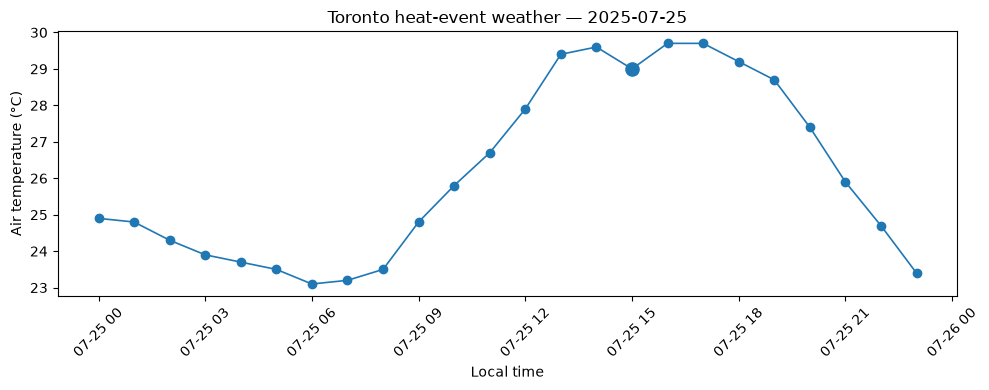

In [8]:
event_row = weather_df[
    weather_df[
        "datetime"
    ].dt.hour
    == EVENT_HOUR
].copy()

if len(event_row) != 1:
    raise RuntimeError(
        f"Expected exactly one {EVENT_HOUR:02d}:00 record, "
        f"found {len(event_row)}."
    )

selected = event_row.iloc[0]

fig, ax = plt.subplots(
    figsize=(10, 4)
)

ax.plot(
    weather_df["datetime"],
    weather_df["ta_C"],
    marker="o",
    linewidth=1.2,
)

ax.scatter(
    [selected["datetime"]],
    [selected["ta_C"]],
    s=90,
    zorder=10,
)

ax.set_title(
    f"Toronto heat-event weather — {EVENT_DATE}"
)

ax.set_ylabel(
    "Air temperature (°C)"
)

ax.set_xlabel(
    "Local time"
)

plt.xticks(
    rotation=45
)

plt.tight_layout()
plt.show()

## 9. Inspect the selected 15:00 weather conditions

In [9]:
selected_datetime = pd.Timestamp(
    selected["datetime"]
)

ta = float(
    selected["ta_C"]
)

rh = float(
    selected["rh_pct"]
)

ws = float(
    selected["wind_ms"]
)

global_rad = float(
    selected["global_rad_Wm2"]
)

print(
    "Selected local datetime:",
    selected_datetime,
)

print(
    "Air temperature:",
    ta,
    "°C",
)

print(
    "Relative humidity:",
    rh,
    "%",
)

print(
    "Wind speed:",
    ws,
    "m/s",
)

print(
    "Shortwave/global radiation:",
    global_rad,
    "W/m²",
)

Selected local datetime: 2025-07-25 15:00:00
Air temperature: 29.0 °C
Relative humidity: 51.0 %
Wind speed: 0.78 m/s
Shortwave/global radiation: 556.0 W/m²


## 10. Sanity-check the selected weather values

The simulation stops if key meteorological values are missing or obviously
outside physically reasonable bounds.

In [10]:
checks = {
    "ta_C": ta,
    "rh_pct": rh,
    "wind_ms": ws,
    "global_rad_Wm2": global_rad,
}

for key, value in checks.items():
    if not np.isfinite(value):
        raise RuntimeError(
            f"Missing or invalid weather value: {key}"
        )

if not (-40 <= ta <= 50):
    raise RuntimeError(
        f"Unexpected air temperature: {ta}"
    )

if not (0 <= rh <= 100):
    raise RuntimeError(
        f"Unexpected relative humidity: {rh}"
    )

if ws < 0:
    raise RuntimeError(
        f"Unexpected wind speed: {ws}"
    )

if global_rad < 0:
    raise RuntimeError(
        f"Unexpected shortwave radiation: {global_rad}"
    )

print(
    "✓ Weather values passed basic sanity checks."
)

✓ Weather values passed basic sanity checks.


## 11. Build the SOLWEIG weather object

SOLWEIG accepts a manual single-timestep weather object.

Wind speed is included explicitly because it directly affects UTCI.

In [11]:
weather = solweig.Weather(
    datetime=datetime(
        2025,
        7,
        25,
        EVENT_HOUR,
        0,
    ),
    ta=ta,
    rh=rh,
    global_rad=global_rad,
    ws=ws,
)

print(
    "SOLWEIG weather object:"
)

print(
    weather
)

SOLWEIG weather object:
Weather(datetime=datetime.datetime(2025, 7, 25, 15, 0), ta=29.0, rh=51.0, global_rad=556.0, ws=0.78, pressure=1013.25, timestep_minutes=60.0, measured_direct_rad=None, measured_diffuse_rad=None, precomputed_sun_altitude=None, precomputed_sun_azimuth=None, precomputed_altmax=None, sun_altitude=0.0, sun_azimuth=0.0, sun_zenith=90.0, direct_rad=0.0, diffuse_rad=0.0, clearness_index=1.0, altmax=45.0)


## 12. Define the Toronto SOLWEIG location

On 25 July Toronto is observing daylight saving time, so the local UTC offset
is **UTC−4**.

This matters because the solar position controls shadows and radiant exposure.

In [12]:
location = solweig.Location(
    latitude=latitude,
    longitude=longitude,
    utc_offset=-4,
)

print(
    "SOLWEIG location:"
)

print(
    location
)

SOLWEIG location:
Location(latitude=43.66371033567467, longitude=-79.39600762899782, altitude=0.0, utc_offset=-4)


## 13. Run SOLWEIG for the observed-event timestep

Only one common timestep is simulated.

Therefore every cell in the resulting thermal field represents:

**25 July 2025 at 15:00 Toronto local time**

In [13]:
run_dir = (
    SOLWEIG_OUTPUT_DIR
    / "run"
)

run_dir.mkdir(
    parents=True,
    exist_ok=True,
)

summary = solweig.calculate(
    surface=surface,
    weather=[
        weather
    ],
    location=location,
    output_dir=str(
        run_dir
    ),
    outputs=[
        "tmrt",
        "shadow",
    ],
)

print(
    "✓ SOLWEIG event simulation complete."
)

solweig.tiling: Resource-aware tile sizing (context=solweig): GPU budget=2,147,483,647 bytes, RAM=1,540,884,996,096 available of 1,622,112,485,376 total, max_tile_side=2184 px
solweig.timeseries: ============================================================
solweig.timeseries: Starting SOLWEIG timeseries calculation
solweig.timeseries:   Grid size: 416x416 pixels
solweig.timeseries:   Timesteps: 1
solweig.timeseries:   Period: 2025-07-25 15:00 -> 2025-07-25 15:00
solweig.timeseries:   Location: 43.66N, -79.40E
solweig.timeseries: ============================================================
solweig.timeseries: Pre-computing sun positions and radiation splits...
solweig.timeseries:   Pre-computed 1 timesteps in 0.0s


error: XDG_RUNTIME_DIR is invalid or not set in the environment.
[GPU] Shadow GPU context initialized successfully
SOLWEIG timeseries:   0%|          | 0/1 [00:00<?, ?it/s]

solweig.timeseries:   SOLWEIG timeseries: pre-computing ground view factor (reused across 1 timestep)


[GPU] GVF GPU context initialized
[GPU] Anisotropic sky GPU context initialized
SOLWEIG timeseries: 100%|██████████| 1/1 [00:00<00:00,  2.12it/s]

solweig.timeseries: ============================================================
solweig.timeseries: Calculation complete: 1 timesteps processed
solweig.timeseries:   Total time: 0.5s (2.08 steps/s)
solweig.timeseries: ============================================================


✓ SOLWEIG event simulation complete.


## 14. Inspect the SOLWEIG run summary

In [14]:
try:
    print(
        summary.report()
    )
except Exception:
    print(
        summary
    )

SOLWEIG Summary: 1 timesteps (1 day, 0 night)
  Period: 2025-07-25 15:00 — 2025-07-25 15:00
  Tmrt  — mean: 53.7°C, range: 29.6 – 56.3°C
  UTCI  — mean: 35.7°C, range: 29.4 – 36.4°C
  Sun   — 0.0 – 1.0 hours
  UTCI > 32°C (day) — max 1.0h
  Ta    — range: 29.0 – 29.0°C
  Summary GeoTIFFs: /scratch/project_2010417/paper3/heat-conditioned-accessibility/outputs/toronto/solweig/UOFT_PILOT_2025-07-25_1500/run/summary/
    shade_hours.tif
    sun_hours.tif
    tmrt_day_mean.tif
    tmrt_max.tif
    tmrt_mean.tif
    tmrt_min.tif
    tmrt_night_mean.tif
    utci_day_mean.tif
    utci_hours_above_26_night.tif
    utci_hours_above_32_day.tif
    utci_hours_above_38_day.tif
    utci_max.tif
    utci_mean.tif
    utci_min.tif
    utci_night_mean.tif

Tip: per-timestep arrays are in summary.timeseries (e.g. .ta, .tmrt_mean, .utci_mean).
     Spatial grids are on the summary itself (e.g. .tmrt_mean, .utci_max).
     Summary grids are saved as GeoTIFFs above; timeseries arrays are in memory only.


## 15. Extract common-time Tmrt and UTCI

In [15]:
tmrt_event = np.asarray(
    summary.tmrt_mean,
    dtype=np.float32,
)

utci_event = np.asarray(
    summary.utci_mean,
    dtype=np.float32,
)

print(
    "Tmrt min/mean/max:",
    float(np.nanmin(tmrt_event)),
    float(np.nanmean(tmrt_event)),
    float(np.nanmax(tmrt_event)),
)

print(
    "UTCI min/mean/max:",
    float(np.nanmin(utci_event)),
    float(np.nanmean(utci_event)),
    float(np.nanmax(utci_event)),
)

print(
    "UTCI SD:",
    float(np.nanstd(utci_event)),
)

Tmrt min/mean/max: 29.57440185546875 53.67216873168945 56.292266845703125
UTCI min/mean/max: 29.449005126953125 35.70380783081055 36.364173889160156
UTCI SD: 0.6367783546447754


## 16. Save the event Tmrt and UTCI rasters

In [16]:
with rasterio.open(
    dsm_path
) as src:

    output_profile = (
        src.profile.copy()
    )

output_profile.update(
    dtype="float32",
    count=1,
    compress="lzw",
)


def save_raster(
    path,
    array,
):

    expected_shape = (
        output_profile[
            "height"
        ],
        output_profile[
            "width"
        ],
    )

    if array.shape != expected_shape:
        raise RuntimeError(
            f"Raster shape {array.shape} "
            f"does not match expected {expected_shape}."
        )

    with rasterio.open(
        path,
        "w",
        **output_profile,
    ) as dst:

        dst.write(
            array.astype(
                np.float32
            ),
            1,
        )


tmrt_path = (
    SOLWEIG_OUTPUT_DIR
    / "tmrt_2025-07-25_1500.tif"
)

utci_path = (
    SOLWEIG_OUTPUT_DIR
    / "utci_2025-07-25_1500.tif"
)

save_raster(
    tmrt_path,
    tmrt_event,
)

save_raster(
    utci_path,
    utci_event,
)

print("Saved:")
print("-", tmrt_path)
print("-", utci_path)

rasterio._env: CPLE_IllegalArg in tmrt_2025-07-25_1500.tif: BLOCKXSIZE can only be used with TILED=YES
rasterio._env: CPLE_IllegalArg in utci_2025-07-25_1500.tif: BLOCKXSIZE can only be used with TILED=YES
Saved:
- /scratch/project_2010417/paper3/heat-conditioned-accessibility/outputs/toronto/solweig/UOFT_PILOT_2025-07-25_1500/tmrt_2025-07-25_1500.tif
- /scratch/project_2010417/paper3/heat-conditioned-accessibility/outputs/toronto/solweig/UOFT_PILOT_2025-07-25_1500/utci_2025-07-25_1500.tif


## 17. Visualize the event thermal fields

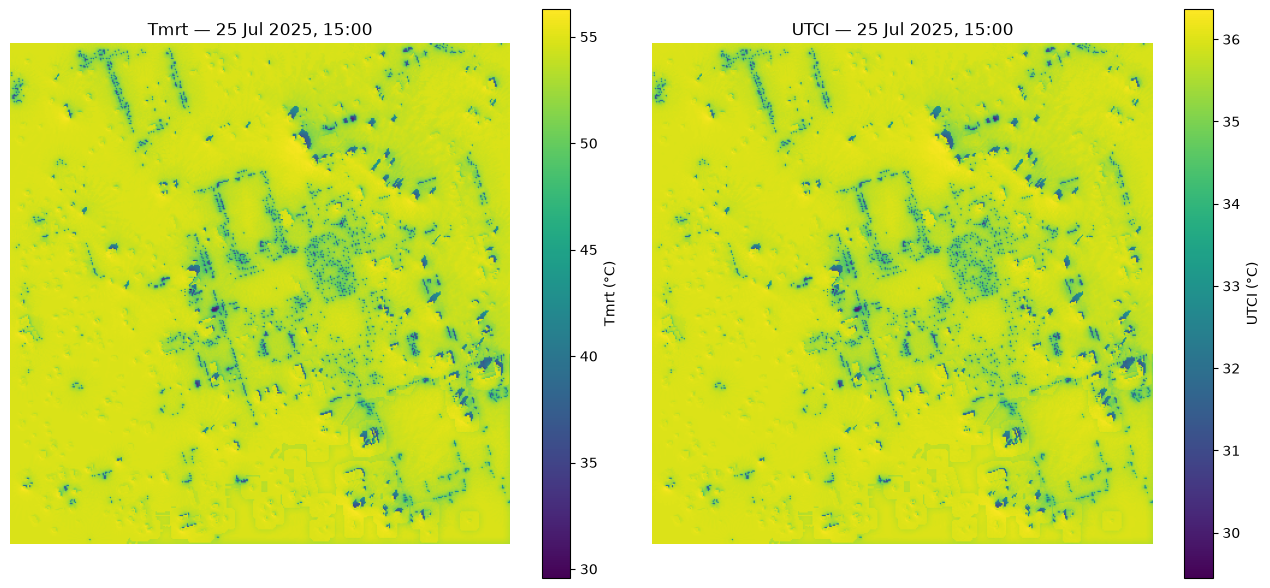

In [17]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(13, 6),
)

image0 = axes[0].imshow(
    tmrt_event,
    origin="upper",
)

axes[0].set_title(
    "Tmrt — 25 Jul 2025, 15:00"
)

plt.colorbar(
    image0,
    ax=axes[0],
    label="Tmrt (°C)",
)


image1 = axes[1].imshow(
    utci_event,
    origin="upper",
)

axes[1].set_title(
    "UTCI — 25 Jul 2025, 15:00"
)

plt.colorbar(
    image1,
    ax=axes[1],
    label="UTCI (°C)",
)

for ax in axes:
    ax.set_axis_off()

plt.tight_layout()
plt.show()

## 18. Quantify spatial thermal heterogeneity

This is one of the critical diagnostics for Toronto v2.

Sevilla's daily-maximum UTCI surface produced very little spatial contrast.
A common observed-event timestep should preserve more meaningful variation
associated with shade, canopy, and urban geometry.

In [18]:
thermal_stats = {
    "utci_min_C": float(
        np.nanmin(
            utci_event
        )
    ),
    "utci_p05_C": float(
        np.nanpercentile(
            utci_event,
            5,
        )
    ),
    "utci_mean_C": float(
        np.nanmean(
            utci_event
        )
    ),
    "utci_median_C": float(
        np.nanmedian(
            utci_event
        )
    ),
    "utci_p95_C": float(
        np.nanpercentile(
            utci_event,
            95,
        )
    ),
    "utci_max_C": float(
        np.nanmax(
            utci_event
        )
    ),
    "utci_sd_C": float(
        np.nanstd(
            utci_event
        )
    ),
    "tmrt_mean_C": float(
        np.nanmean(
            tmrt_event
        )
    ),
    "tmrt_sd_C": float(
        np.nanstd(
            tmrt_event
        )
    ),
}

for key, value in thermal_stats.items():
    print(
        f"{key}: {value}"
    )

utci_min_C: 29.449005126953125
utci_p05_C: 35.01179504394531
utci_mean_C: 35.70380783081055
utci_median_C: 35.88092803955078
utci_p95_C: 36.030025482177734
utci_max_C: 36.364173889160156
utci_sd_C: 0.6367783546447754
tmrt_mean_C: 53.67216873168945
tmrt_sd_C: 2.4911720752716064


## 19. Thermal-stress threshold diagnostics

In [19]:
valid_utci = utci_event[
    np.isfinite(
        utci_event
    )
]

thresholds = [
    26,
    32,
    38,
]

threshold_rows = []

for threshold in thresholds:

    threshold_rows.append(
        {
            "threshold_C": threshold,
            "share_cells_above": float(
                np.mean(
                    valid_utci > threshold
                )
            ),
        }
    )

display(
    pd.DataFrame(
        threshold_rows
    )
)

,threshold_C,share_cells_above
0,26,1.000000
1,32,0.990962
2,38,0.000000


## 20. Save reproducibility metadata

In [20]:
scenario_metadata = {
    "scenario_name": (
        "UOFT_PILOT_2025-07-25_1500"
    ),
    "event_date": EVENT_DATE,
    "event_local_hour": EVENT_HOUR,
    "timezone": TORONTO_TIMEZONE,
    "heat_warning_context": (
        "Toronto documented heat-warning period "
        "23-30 July 2025"
    ),
    "weather_source": (
        "Open-Meteo historical archive at U of T coordinates"
    ),
    "weather_interpretation": (
        "historical gridded weather reconstruction; "
        "not a single-station observation"
    ),
    "latitude": latitude,
    "longitude": longitude,
    "air_temperature_C": ta,
    "relative_humidity_pct": rh,
    "wind_speed_ms": ws,
    "global_shortwave_radiation_Wm2": global_rad,
    "utc_offset_used_by_solweig": -4,
    "tmrt_raster": str(
        tmrt_path
    ),
    "utci_raster": str(
        utci_path
    ),
}

metadata_path = (
    SOLWEIG_OUTPUT_DIR
    / "scenario_metadata.json"
)

with open(
    metadata_path,
    "w",
    encoding="utf-8",
) as handle:

    json.dump(
        scenario_metadata,
        handle,
        indent=2,
    )

print(
    "Saved:",
    metadata_path,
)

Saved: /scratch/project_2010417/paper3/heat-conditioned-accessibility/outputs/toronto/solweig/UOFT_PILOT_2025-07-25_1500/scenario_metadata.json


## 21. Final scenario summary

In [21]:
print(
    "Event:",
    EVENT_DATE,
    f"{EVENT_HOUR:02d}:00",
    TORONTO_TIMEZONE,
)

print(
    "Air temperature:",
    ta,
    "°C",
)

print(
    "Relative humidity:",
    rh,
    "%",
)

print(
    "Wind speed:",
    ws,
    "m/s",
)

print(
    "Global radiation:",
    global_rad,
    "W/m²",
)

print()

print(
    "UTCI mean:",
    round(
        float(
            np.nanmean(
                utci_event
            )
        ),
        2,
    ),
    "°C",
)

print(
    "UTCI SD:",
    round(
        float(
            np.nanstd(
                utci_event
            )
        ),
        2,
    ),
    "°C",
)

print(
    "UTCI range:",
    round(
        float(
            np.nanmin(
                utci_event
            )
        ),
        2,
    ),
    "to",
    round(
        float(
            np.nanmax(
                utci_event
            )
        ),
        2,
    ),
    "°C",
)

print()

print(
    "Primary network thermal raster:"
)

print(
    utci_path
)

Event: 2025-07-25 15:00 America/Toronto
Air temperature: 29.0 °C
Relative humidity: 51.0 %
Wind speed: 0.78 m/s
Global radiation: 556.0 W/m²

UTCI mean: 35.7 °C
UTCI SD: 0.64 °C
UTCI range: 29.45 to 36.36 °C

Primary network thermal raster:
/scratch/project_2010417/paper3/heat-conditioned-accessibility/outputs/toronto/solweig/UOFT_PILOT_2025-07-25_1500/utci_2025-07-25_1500.tif


## Interpretation and next step

The Toronto thermal experiment is now anchored to a **documented heat-warning
period and a fixed common afternoon time**.

This is a stronger design than selecting the hottest hour from a typical
meteorological year because the scenario corresponds to a specific historical
Toronto heat event.

The main thermal raster for the next stage is:

**`utci_2025-07-25_1500.tif`**

Continue to:

**`06_toronto_thermal_network.ipynb`**

The key diagnostic there will be whether the observed-event common-time UTCI
field produces more heterogeneous edge-level thermal penalties than the
Sevilla daily-maximum stress-test surface.